In [4]:
import pandas as pd

df_train = pd.read_csv("train_data.csv")
df_test = pd.read_csv("test_data.csv")

df_train.head()

,MSSubClass,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,text
0,75,RL,Pave,NaN,Reg,Bnk,AllPub,Inside,Mod,SWISU,...,NaN,NaN,NaN,0,7,2008,WD,Normal,179500,\n\nThis property boasts a stunning kitchen th...
1,20,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,NaN,NaN,NaN,0,3,2010,WD,Normal,162000,\n\nThis charming ranch home boasts 1 fireplac...
2,20,RL,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,NaN,MnPrv,NaN,0,7,2009,WD,Normal,124500,\n\n**Kitchen quality** | **TA**\n\nThis charm...
3,70,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,NaN,MnPrv,NaN,0,6,2009,WD,Normal,234000,UNK
4,20,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Edwards,...,NaN,MnPrv,NaN,0,10,2009,COD,Abnorml,112000,\n\n**Property Details:**\n\n* Year Sold: 2009...


In [5]:
features = [col for col in df_test.columns if col != 'ID' and col != 'text']
target = 'SalePrice'

X = df_train[features]
y = df_train[target]

X_final = df_test[features]

X.head()

,MSSubClass,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,75,RL,Pave,NaN,Reg,Bnk,AllPub,Inside,Mod,SWISU,...,0,0,NaN,NaN,NaN,0,7,2008,WD,Normal
1,20,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,...,182,0,NaN,NaN,NaN,0,3,2010,WD,Normal
2,20,RL,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,...,0,0,NaN,MnPrv,NaN,0,7,2009,WD,Normal
3,70,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,...,145,0,NaN,MnPrv,NaN,0,6,2009,WD,Normal
4,20,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Edwards,...,160,0,NaN,MnPrv,NaN,0,10,2009,COD,Abnorml


In [6]:
#preprocessing
to_drop = ["Alley", "PoolQC", "Fence", "MiscFeature"]

X = X.drop(columns=to_drop)
X_final = X_final.drop(columns=to_drop)

cat_features = [col for col in X.columns if X[col].dtype == 'object']
to_impute = ["MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "Electrical", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond"]

from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='most_frequent')
X[to_impute] = imputer.fit_transform(X[to_impute])
X_final[to_impute] = imputer.transform(X_final[to_impute])

In [7]:
from sklearn.preprocessing import LabelEncoder
for col in cat_features:
    enc = LabelEncoder()
    enc.fit(pd.concat([X[col], X_final[col]]))
    X[col] = enc.transform(X[col])
    X_final[col] = enc.transform(X_final[col])

X.head()

,MSSubClass,MSZoning,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,PavedDrive,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,75,3,1,3,0,0,4,1,18,2,...,2,0,0,0,0,0,7,2008,8,4
1,20,3,1,0,3,0,0,0,12,2,...,2,0,0,182,0,0,3,2010,8,4
2,20,3,1,3,3,0,0,0,12,2,...,2,0,0,0,0,0,7,2009,8,4
3,70,3,1,3,3,0,4,0,6,2,...,2,0,0,145,0,0,6,2009,8,4
4,20,3,1,0,3,0,0,0,7,2,...,2,0,0,160,0,0,10,2009,0,0


In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X))
X_final = pd.DataFrame(scaler.transform(X_final))

In [9]:
X_text = df_train['text']
X_text_final = df_test['text']

X_text[2]

'\n\n**Kitchen quality** | **TA**\n\nThis charming home boasts a fully equipped kitchen, perfect for culinary enthusiasts!'

In [10]:
import re

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

preprocess(X_text[2])

'kitchen quality tathis charming home boasts a fully equipped kitchen perfect for culinary enthusiasts'

In [11]:
X_text = X_text.apply(preprocess)
X_text_final = X_text_final.apply(preprocess)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
vect = TfidfVectorizer()
X_text = vect.fit_transform(X_text)
X_text_final = vect.transform(X_text_final)

X_text

<1168x706 sparse matrix of type '<class 'numpy.float64'>'
	with 16590 stored elements in Compressed Sparse Row format>

In [13]:
from scipy.sparse import hstack
X_comb = hstack([X, X_text])
X_comb_final = hstack([X_final, X_text_final])

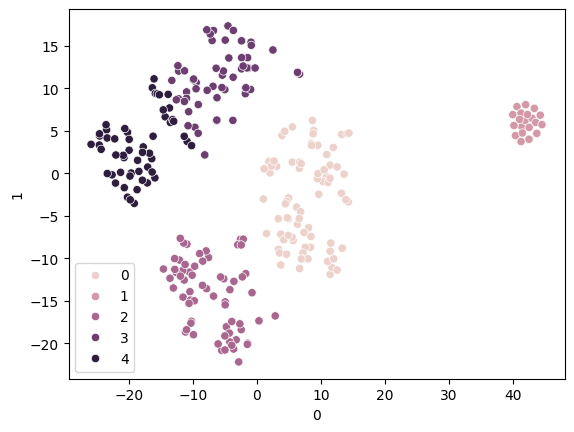

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

decom = TSNE(n_components=2, init='random')
X_red = pd.DataFrame(decom.fit_transform(X_text_final))

kmeans = KMeans(n_clusters=5, random_state=42)
labels = kmeans.fit_predict(X_red)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [15]:
df_1 = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.ID,
    "answer": labels
})

df_1.head()

,subtaskID,datapointID,answer
0,1,0,0
1,1,1,0
2,1,2,2
3,1,3,0
4,1,4,0


In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV

model = GradientBoostingRegressor()

cross_val_score(model, X, y, cv=3, scoring='r2').mean()

0.6958320272581956

In [23]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [24]:
df_2 = pd.DataFrame({
    "subtaskID": 2,
    "datapointID": df_test.ID,
    "answer": y_preds
})

df_2.head()

,subtaskID,datapointID,answer
0,2,0,223551.394519
1,2,1,430269.293801
2,2,2,199726.087938
3,2,3,255691.621213
4,2,4,190077.234302


In [25]:
submission = pd.concat([df_1, df_2])
submission.to_csv("submission.csv", index=False)

In [26]:
submission

,subtaskID,datapointID,answer
0,1,0,4.000000
1,1,1,4.000000
2,1,2,1.000000
3,1,3,0.000000
4,1,4,4.000000
...,...,...,...
287,2,287,102774.358450
288,2,288,224401.999620
289,2,289,190791.608177
290,2,290,135021.995563
